# Performance benchmark: LPRec3D ToMoBAR on I13 dataset 2

Measure ten LPRec3D reconstructions of all ten detector rows in I13 dataset 2.
Use quantitative scaling (`legacy_scaling=False`), an untimed warm-up and
individually synchronised measurements.

## Data and execution

Use `i13_dataset2.npz` from [Zenodo record 17252190](https://zenodo.org/records/17252190).
The repository downloader verifies the archive checksums.
Run from the repository root:

```bash
python .scripts/download_zenodo.py Zenodo
python -m pip install -e '.[validation]'
python -m pytest --nbmake --nbmake-timeout=1800 --overwrite docs/source/benchmarks/lprec3d_i13_dataset2.ipynb
```

Use an NVIDIA GPU with compatible CuPy and ToMoBAR installed, plus ASTRA for
ASTRA-based reconstruction. Run notebooks serially. Set `HTTOMOLIBGPU_DATA_DIR`
to use an archive stored elsewhere.

Documentation builds render saved outputs without running GPU computations.
Execute with `--overwrite` before building documentation to update the results.


In [1]:
import gc
import math
import pytest
import hashlib
import json
import os
import platform
from importlib.metadata import version
from pathlib import Path

import cupy as cp
import matplotlib.pyplot as plt
import numpy as np
from numpy.testing import assert_allclose

from httomolibgpu.prep.normalize import dark_flat_field_correction, minus_log
from httomolibgpu.recon.algorithm import LPRec3d_tomobar

# Locate the checkout from either the repository root or the notebook directory.
repo_root = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "pyproject.toml").is_file() and (p / "httomolibgpu").is_dir()
    ),
    None,
)
data_dir = os.environ.get("HTTOMOLIBGPU_DATA_DIR")
if data_dir is None:
    if repo_root is None:
        raise FileNotFoundError(
            "Set HTTOMOLIBGPU_DATA_DIR to the Zenodo archive directory"
        )
    data_dir = repo_root / "Zenodo"
data_path = Path(data_dir).expanduser() / "i13_dataset2.npz"
if not data_path.is_file():
    raise FileNotFoundError(
        f"Missing {data_path}; run .scripts/download_zenodo.py first"
    )

checksum = hashlib.sha256()
with data_path.open("rb") as stream:
    for chunk in iter(lambda: stream.read(1024 * 1024), b""):
        checksum.update(chunk)
props = cp.cuda.runtime.getDeviceProperties(cp.cuda.Device().id)
provenance = {
    "dataset": data_path.name,
    "zenodo_record": "17252190",
    "sha256": checksum.hexdigest(),
    "python": platform.python_version(),
    "packages": {
        name: version(name)
        for name in ("httomolibgpu", "tomobar", "astra-toolbox", "numpy")
    },
    "cupy": cp.__version__,
    "cuda_runtime": cp.cuda.runtime.runtimeGetVersion(),
    "cuda_driver": cp.cuda.runtime.driverGetVersion(),
    "gpu": (
        props["name"].decode() if isinstance(props["name"], bytes) else props["name"]
    ),
}
print(json.dumps(provenance, indent=2))

{
  "dataset": "i13_dataset2.npz",
  "zenodo_record": "17252190",
  "sha256": "11281ab163dd105ae5e550a411a5310d4156852a377eb058e66a765c68748461",
  "python": "3.14.7",
  "packages": {
    "httomolibgpu": "6.0.1.post16+git.bbaa03d2.dirty",
    "tomobar": "2026.3.1.0",
    "astra-toolbox": "2.5.0",
    "numpy": "2.4.6"
  },
  "cupy": "14.2.0",
  "cuda_runtime": 13020,
  "cuda_driver": 13020,
  "gpu": "NVIDIA GeForce RTX 4060"
}


## Preprocessing

Apply default dark/flat correction and negative logarithm to the complete dataset.
Do not include data loading, preprocessing, validation or plotting in timing.


In [2]:
with np.load(data_path) as archive:
    projdata = cp.asarray(archive["projdata"])
    flats = cp.asarray(archive["flats"])
    darks = cp.asarray(archive["darks"])
    angles = archive["angles"].copy()
data_normalised = minus_log(dark_flat_field_correction(projdata, flats, darks))
del projdata, flats, darks
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
assert bool(cp.isfinite(data_normalised).all())
print("Corrected input:", data_normalised.shape)

Corrected input: (2501, 10, 2560)


## Timing protocol

Use centre 1286.25 pixels and no detector padding, with explicit filter and mask
settings. Synchronise before and after each reconstruction. Each sample includes
the wrapper call, output allocation and cache management; output deletion and
NVTX range setup are excluded. Use one warm-up and ten measured runs.
Require finite, positive timings and compare results only when hardware,
software, parameters and timing protocol match.


In [3]:
import time
from cupy.cuda import nvtx

dev = cp.cuda.Device()
recon_angles = np.deg2rad(angles)
parameters = {
    "center": 1286.25,
    "detector_pad": 0,
    "filter_type": "shepp",
    "filter_freq_cutoff": 1.0,
    "recon_mask_radius": 0.95,
    "legacy_scaling": False,
}
repeats = 10
print("Parameters:", parameters)
# Warm-up is excluded from reported timings.
warmup = LPRec3d_tomobar(data_normalised, recon_angles, **parameters)
dev.synchronize()
assert warmup.shape == (2560, 10, 2560)
assert warmup.dtype == cp.float32
assert warmup.flags.c_contiguous
assert bool(cp.isfinite(warmup).all())
# Transfer one slice for review outside the measured region.
preview = warmup[:, warmup.shape[1] // 2, :].get()
del warmup

timings_ms = []
for iteration in range(repeats):
    dev.synchronize()
    nvtx.RangePush("LPRec3D reconstruction")
    try:
        start = time.perf_counter_ns()
        recon = LPRec3d_tomobar(data_normalised, recon_angles, **parameters)
        dev.synchronize()
        timings_ms.append((time.perf_counter_ns() - start) / 1e6)
    finally:
        nvtx.RangePop()
    del recon

timings_ms = np.asarray(timings_ms)
assert np.isfinite(timings_ms).all() and (timings_ms > 0).all()
summary = {
    "repeats": repeats,
    "units": "ms",
    "mean": float(timings_ms.mean()),
    "median": float(np.median(timings_ms)),
    "std_sample": float(timings_ms.std(ddof=1)),
    "minimum": float(timings_ms.min()),
    "maximum": float(timings_ms.max()),
    "individual_runs": timings_ms.tolist(),
}
print(json.dumps(summary, indent=2))

Parameters: {'center': 1286.25, 'detector_pad': 0, 'filter_type': 'shepp', 'filter_freq_cutoff': 1.0, 'recon_mask_radius': 0.95, 'legacy_scaling': False}


{
  "repeats": 10,
  "units": "ms",
  "mean": 231.08660440000003,
  "median": 231.239575,
  "std_sample": 2.369146068966585,
  "minimum": 226.928443,
  "maximum": 234.264737,
  "individual_runs": [
    227.847237,
    231.127311,
    230.076578,
    231.201365,
    231.277785,
    234.224287,
    231.649241,
    226.928443,
    234.264737,
    232.26906
  ]
}


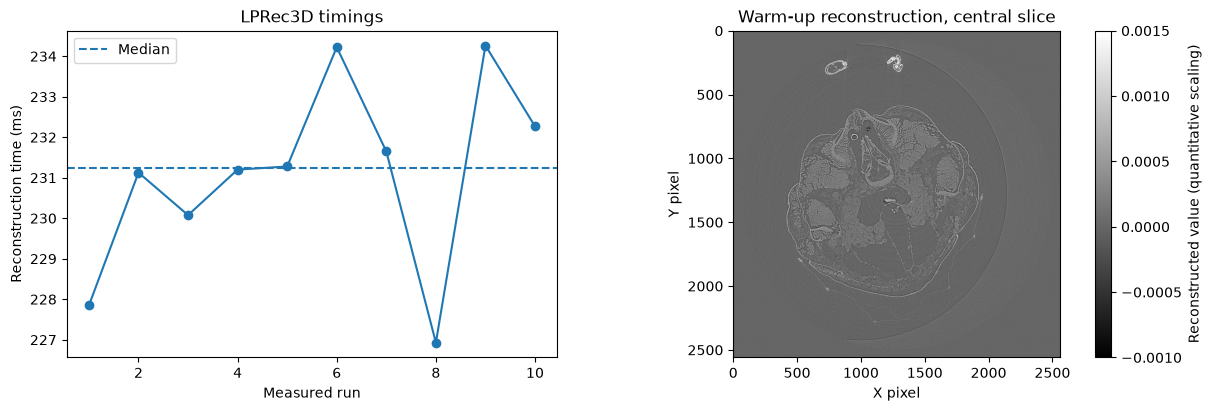

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(np.arange(1, repeats + 1), timings_ms, "o-")
axes[0].axhline(np.median(timings_ms), linestyle="--", label="Median")
axes[0].set(
    xlabel="Measured run", ylabel="Reconstruction time (ms)", title="LPRec3D timings"
)
axes[0].legend()
im = axes[1].imshow(preview, cmap="gray", vmin=-0.001, vmax=0.0015)
axes[1].set(
    title="Warm-up reconstruction, central slice", xlabel="X pixel", ylabel="Y pixel"
)
fig.colorbar(im, ax=axes[1], label="Reconstructed value (quantitative scaling)")
plt.show()
plt.close(fig)

## Interpretation

Mean, median, sample standard deviation and individual timings describe this
machine and run. Background GPU activity, thermal state and dependency versions
can affect results. The preview and structural checks confirm a usable output;
this is not the I13 quantitative image-quality validation. Establish a baseline on
a defined benchmark machine before introducing a performance failure threshold.


In [5]:
del data_normalised, preview
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
cp.get_default_pinned_memory_pool().free_all_blocks()